# Workflows First: A Gated Contract Review, Measured Against an Agent

**A supplier contract arrives as a 38-page scan with no text layer. A three-step chain extracts nothing from it, finds nothing wrong, and writes a memo that says so. This notebook builds the same contract review three ways: that chain, an agent that picks its own steps, and a fixed workflow with gates between the steps. It scores all three against planted ground truth, including five files a person must see, and reports where the agent did better.**

## The one idea

A **workflow** runs model calls along a path your code fixes in advance. An **agent** lets the model choose its next step and its tools until the job is done ([Anthropic, 2024](https://www.anthropic.com/engineering/building-effective-agents)). Many jobs that look like agent work are a fixed path with a few checks.

What makes that path trustworthy is the **gate**: plain code between two steps that reads the output and returns one of three verdicts. Pass it on, retry the step with the reason it failed, or exit to a person. A gate checks *shape* (the output parses), *sanity* (it fits the input: a three-page contract states its payment terms) and *grounding* (every quote exists in the source). A gate runs on every file. An agent's judgment runs when the model thinks of it.

## Overview

1. Build 18 synthetic contract files with planted terms, near misses and five files a person must see, so every run is scored exactly
2. Write the workflow: two model calls and the policy rules in code, in an order the code sets, with two gates
3. Run it with the gates switched off, the way the chain in the hook ran
4. Give the same job to an agent with three tools, run it three times, and once more with reasoning off
5. Switch the gates on and run the workflow three times
6. Compare routes, flags, files caught, calls, tokens, cost, time and run-to-run spread, then read every mistake
7. Add the gate nobody wrote, and test it on the saved runs without a single model call

**Requirements:** `pip install openai tiktoken matplotlib numpy` and an `OPENAI_API_KEY`. The eight runs make 324 calls to `gpt-5.4-mini` and cost about $0.33 together at the list prices of 2026-10-30. The whole notebook ran in about two minutes. Every call goes through the Responses API, because on Chat Completions this model accepts function tools only with reasoning switched off. Outputs saved in this notebook come from a real run. Yours will differ a little, because the model is not deterministic.

> 📖 This notebook is the hands-on side of Chapter 3, "Workflows First", of [*AI Agents Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-agents-tutorials--workflows-first-from-scratch&click=book-nb-agents-top&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0HNXRSRH2%3Fmaas%3Dmaas_adg_api_580351185840460851_static_9_573%26ref_%3Daa_maas%26tag%3Dmaas%26aa_campaignid%3Dagents-en%26aa_adgroupid%3Dgithub-notebook%26aa_creativeid%3Dgenai-workflows-first-top&retarget=0&text=book-nb-agents-top), by the author of this repository.

In [1]:
# !pip install openai tiktoken matplotlib numpy
import json, random, time
from concurrent.futures import ThreadPoolExecutor
from difflib import SequenceMatcher
import openai, tiktoken
import numpy as np
import matplotlib.pyplot as plt

MODEL = "gpt-5.4-mini"
# USD per 1M tokens, from https://developers.openai.com/api/docs/pricing on 2026-10-30. Check yours.
PRICE = {"input": 0.75, "cached_input": 0.075, "output": 4.50}
RUNS = 3                          # the agent and the gated workflow each run this many times, to measure the spread
client = openai.OpenAI()          # reads OPENAI_API_KEY from the environment
enc = tiktoken.get_encoding("o200k_base")   # only used to report file sizes; billing comes from the API

def call_model(effort="none", **kw):
    # Every model call in the notebook goes through here. It uses the Responses API because on
    # Chat Completions this model accepts function tools only with reasoning switched off.
    for attempt in range(5):
        try:
            return client.responses.create(model=MODEL, reasoning={"effort": effort}, **kw)
        except (openai.RateLimitError, openai.APIConnectionError, openai.InternalServerError):
            if attempt == 4: raise
            time.sleep(5 * (attempt + 1))

def usage_of(r):
    u = r.usage
    return {"input": u.input_tokens, "cached": u.input_tokens_details.cached_tokens or 0,
            "output": u.output_tokens, "reasoning": u.output_tokens_details.reasoning_tokens or 0}

def cost(usages):
    i, c, o = (sum(u[k] for u in usages) for k in ("input", "cached", "output"))
    return ((i - c) * PRICE["input"] + c * PRICE["cached_input"] + o * PRICE["output"]) / 1e6

## 1. A job with a known answer

A retailer reviews every supplier contract against a four-rule policy before anyone signs it. One rule decides the route: a contract that renews automatically *and* makes the retailer pay more after a renewal goes to finance before signature. The other three rules (the retailer's liability left unlimited, more than 90 days' notice, payment in fewer than 30 days) become flags in the memo for whoever signs.

The generator writes 18 files and records the right answer for each:

- **12 typed contracts** with the terms planted, including the near misses a careless reader trips on: a price increase on renewal where renewal needs both parties to sign, a contract that "continues" without ever saying "automatically", notice of exactly 90 days, payment in exactly 30, and a liability cap that turns out, one sentence later, to cover the Supplier only.
- **1 contract with OCR typos** (`invoicc`, `withln`). It is readable, so it gets a normal review, but its text is not the clean text a model tends to quote back.
- **5 files a person must see:** a 38-page scan with no text layer, a 22-page file whose text stops after page 1, a 3-page contract whose middle page is a scanned insert, an upside-down scan whose OCR text is noise, and a clean contract from the wrong supplier.

The last one is a trap for both sides. The workflow has gates for the first four kinds of broken file, and the agent is told about them too. Nobody wrote a gate for a wrong attachment, or warned the agent about one. Section 7 comes back to it.

In [2]:
CUSTOMER = "Halden Retail Group"
POLICY = """SUPPLIER CONTRACT REVIEW POLICY (before signature)

Rule R - Renewal price increase. If the contract renews automatically (it continues into a new term unless
someone acts to stop it) AND anything makes the Customer pay more after a renewal (a fee increase, an index
uplift, or a discount that ends), finance must approve it before signature. Flag: AUTO_RENEWAL_PRICE_INCREASE.
Rule L - Liability. The Customer's own liability must be limited. If the contract leaves it unlimited, flag
UNCAPPED_LIABILITY. The standard carve-outs for fraud, death and personal injury do not count.
Rule N - Notice. If the notice needed to end the contract for convenience, or to stop a renewal, is more than
90 days, flag LONG_NOTICE. Exactly 90 days is allowed.
Rule P - Payment. If invoices must be paid in fewer than 30 days, flag SHORT_PAYMENT_TERMS. Exactly 30 days is allowed.

Route: "finance" if Rule R applies, otherwise "standard". The other flags go in the memo for the person who signs."""
FLAGS = ["AUTO_RENEWAL_PRICE_INCREASE", "UNCAPPED_LIABILITY", "LONG_NOTICE", "SHORT_PAYMENT_TERMS"]

SUPPLIERS = [("Harbor Line Logistics", "warehousing and last-mile delivery of store stock"),
             ("Bluestem Office Supply", "office consumables for head office and the regional depots"),
             ("Cobalt Cloud Hosting", "managed hosting for the e-commerce platform"),
             ("Kestrel Freight", "full-truckload freight between the two distribution centres"),
             ("Ironbark Security", "manned guarding and alarm response at 14 stores"),
             ("Meadow Facilities", "cleaning and minor maintenance at head office"),
             ("Quarry Analytics", "a sales forecasting dashboard and monthly model refreshes"),
             ("Saltmarsh Catering", "staff canteen catering at the main distribution centre"),
             ("Juniper Print", "in-store signage and seasonal point-of-sale printing"),
             ("Larkspur Translation", "translation of product labels into four languages"),
             ("Granite Payroll", "payroll processing for 2,300 employees"),
             ("Orchard Telecom", "store broadband and backup 4G links"),
             ("Pinecrest Waste", "waste collection and recycling at 30 stores"),
             ("Riverbend Couriers", "same-day courier service for online orders"),
             ("Tidewater IT Support", "a service desk and on-site IT support"),
             ("Willow Recruitment", "temporary staffing for the peak season"),
             ("Fernhill Energy", "electricity supply for 30 stores"),
             ("Ashgrove Insurance Brokers", "broking for the property insurance programme")]

# The 12 typed contracts: what each one really says. Near misses are marked.
#           (renewal,        price at renewal, liability,           notice, payment)
TYPED = [("auto",          "increase",       "capped",              60, 45),
         ("auto",          "fixed",          "capped",              90, 30),   # exactly 90 and 30 days: allowed
         ("by_signature",  "increase",       "capped",              30, 60),   # an increase, but renewal is not automatic
         ("continues",     "discount_ends",  "capped_amount",      120, 45),   # renews without the word "automatically"
         ("auto",          "index",          "customer_unlimited",  60, 20),
         ("ends",          "fixed",          "supplier_only",       45, 30),   # the cap covers the Supplier only
         ("auto",          "agreed_only",    "capped",             180, 15),   # renews, but no increase without consent
         ("continues",     "fixed",          "capped_amount",       90, 45),
         ("by_signature",  "discount_ends",  "capped",              60, 30),   # a discount ends, but renewal is not automatic
         ("auto",          "increase",       "supplier_only",       90, 60),
         ("ends",          "fixed",          "capped",             120, 25),
         ("continues",     "index",          "capped",              30, 45)]
ODD = ["scan_no_text", "partial_text", "missing_page", "ocr_noise", "wrong_file"]   # files a person must see

def truth_of(renewal, price, liability, notice, payment):
    flags = set()
    if renewal in ("auto", "continues") and price in ("increase", "index", "discount_ends"):
        flags.add("AUTO_RENEWAL_PRICE_INCREASE")
    if liability in ("customer_unlimited", "supplier_only"): flags.add("UNCAPPED_LIABILITY")
    if notice > 90: flags.add("LONG_NOTICE")
    if payment < 30: flags.add("SHORT_PAYMENT_TERMS")
    return ("finance" if "AUTO_RENEWAL_PRICE_INCREASE" in flags else "standard"), flags

def write_contract(rng, cid, supplier, service, renewal, price, liability, notice, payment):
    p, months = rng.choice([4, 5, 6, 7, 8]), rng.choice([12, 24, 36])
    price_clause = {
        "increase": f"At the start of each Renewal Term the Fees increase by {p}%.",
        "index": f"At each renewal the Supplier may increase the Fees by the annual change in the consumer price index plus {p // 2}%.",
        "discount_ends": f"The introductory discount of {p * 2}% shown in Schedule B applies during the Initial Term only. From the first Renewal Term the list prices in Schedule B apply.",
        "fixed": "The Fees are fixed for the Initial Term and for every Renewal Term." if renewal != "ends" else "The Fees are fixed for the term of this Agreement.",
        "agreed_only": "The Fees for any Renewal Term stay as set out in Schedule B unless both parties agree a change in writing."}[price]
    renewal_clause = {
        "auto": "After the Initial Term, this Agreement renews automatically for successive periods of 12 months (each a \"Renewal Term\") unless either party gives notice under Section 6.1.",
        "continues": "After the Initial Term, this Agreement continues for successive periods of 12 months (each a \"Renewal Term\") until either party ends it under Section 6.1.",
        "by_signature": "The parties may extend this Agreement for further periods of 12 months (each a \"Renewal Term\") by signing a written extension before the end of the then-current term. Without a signed extension, this Agreement ends at the end of that term.",
        "ends": "This Agreement ends at the end of the Initial Term and does not renew."}[renewal]
    liability_clause = {
        "capped": "7.1 Each party's total liability under this Agreement is limited to the Fees paid or payable in the 12 months before the claim.",
        "capped_amount": "7.1 The Supplier's total liability under this Agreement is limited to the Fees paid in the 12 months before the claim.\n7.2 The Customer's total liability under this Agreement is limited to EUR 250,000.",
        "customer_unlimited": "7.1 The Supplier's total liability under this Agreement is limited to the Fees paid in the 12 months before the claim.\n7.2 Nothing in this Agreement limits the Customer's liability.",
        "supplier_only": "7.1 The Supplier's total liability under this Agreement is limited to the Fees paid in the 12 months before the claim.\n7.2 The limitation in Section 7.1 applies to the Supplier only."}[liability]
    page1 = f"""SUPPLY AGREEMENT  {cid}

1. PARTIES
This Supply Agreement (the "Agreement") is made between {CUSTOMER} (the "Customer") and {supplier} (the "Supplier").

2. DEFINITIONS
"Effective Date" means the date of the last signature below. "Fees" means the charges set out in Schedule B.
"Services" means the services described in Section 3 and Schedule A. "Initial Term" has the meaning in Section 5.1.
"Business Day" means a day other than a weekend or a public holiday in the Customer's home jurisdiction.

3. SERVICES
3.1 The Supplier shall provide {service}, as further described in Schedule A.
3.2 The Supplier shall meet the service levels in Schedule A. If a service level is missed in any month, the Customer
is entitled to a service credit of {rng.choice([2, 3, 5])}% of that month's Fees.
3.3 The Supplier shall respond to written complaints within {rng.choice([5, 10])} Business Days."""
    page2 = f"""4. FEES AND PAYMENT
4.1 The Supplier shall invoice the Fees monthly in arrears.
4.2 The Customer shall pay each undisputed invoice within {payment} days of receipt.
4.3 {price_clause}
4.4 The Supplier may charge interest on late payments at 2% per year above the base rate.

5. TERM AND RENEWAL
5.1 This Agreement starts on the Effective Date and runs for an initial term of {months} months (the "Initial Term").
5.2 {renewal_clause}

6. TERMINATION
6.1 Either party may end this Agreement for convenience by giving the other at least {notice} days' written notice.
6.2 Either party may terminate this Agreement immediately by written notice if the other commits a material breach
that is not remedied within 30 days of being notified of it.

7. LIABILITY
{liability_clause}
7.{3 if liability != "capped" else 2} Neither party limits its liability for fraud, or for death or personal injury caused by its negligence."""
    page3 = f"""8. CONFIDENTIALITY
Each party shall keep the other's confidential information secret and use it only to perform this Agreement.
This obligation survives for {rng.choice([3, 5])} years after this Agreement ends.

9. DATA PROTECTION
The Supplier shall process personal data only on the Customer's documented instructions and shall notify the
Customer of any personal data breach without undue delay, and in any case within {rng.choice([24, 48])} hours.

10. GENERAL
This Agreement is governed by the laws of England and Wales. Notices must be in writing and sent to the addresses
in Schedule C. Schedules A to C form part of this Agreement.

Signed for the Customer: ____________________     Signed for the Supplier: ____________________"""
    return [page1, page2, page3]

def ocr_noise(rng, n_chars):
    junk = "lI1|!i:;.,'`~-_rnmuvwoO0ceaS5$%&()[]{}"
    words = []
    while sum(len(w) + 1 for w in words) < n_chars:
        words.append("".join(rng.choice(junk) for _ in range(rng.randint(1, 7))))
    return " ".join(words)

def ocr_typos(rng, text, rate=0.06):
    # a decent scan, OCR'd with the usual confusions: still readable, but not the original characters
    swaps = {"m": "rn", "l": "1", "o": "0", "e": "c", "i": "l"}
    return "".join(swaps[c] if c in swaps and rng.random() < rate else c for c in text)

def make_files(seed=11):
    rng = random.Random(seed)
    jobs = [("typed", spec) for spec in TYPED] + [("ocr_typos", ("auto", "index", "capped", 60, 45))] + [(k, None) for k in ODD]
    rng.shuffle(jobs)
    suppliers = SUPPLIERS[:]
    rng.shuffle(suppliers)
    files = []
    for i, (kind, spec) in enumerate(jobs):
        cid, (supplier, service) = f"C-{i + 1:02d}", suppliers[i]
        hidden = spec or ("auto", "increase", "capped", 60, 45)   # what the unreadable files really say
        pages = write_contract(rng, cid, supplier, service, *hidden)
        route, flags = truth_of(*hidden)
        if kind == "scan_no_text":            # a scanned PDF: 38 page images and no text layer at all
            pages = [""] * 38
        elif kind == "partial_text":          # a typed first page, then 21 scanned pages with no text layer
            pages = [pages[0]] + [""] * 21
        elif kind == "missing_page":          # page 2 of 3 is a scanned insert with no text layer
            pages = [pages[0], "", pages[2]]
        elif kind == "ocr_typos":             # readable, so it is reviewed like any other contract
            pages = [ocr_typos(rng, p) for p in pages]
        elif kind == "ocr_noise":             # an upside-down scan run through OCR: a text layer of noise
            pages = [ocr_noise(rng, len(p)) for p in pages]
        elif kind == "wrong_file":            # clean and readable, but another supplier's contract
            other, other_service = SUPPLIERS[(SUPPLIERS.index((supplier, service)) + 7) % len(SUPPLIERS)]
            pages = write_contract(rng, cid, other, other_service, *hidden)
        if kind in ODD:
            route, flags = "person", set()
        files.append({"cid": cid, "supplier": supplier, "kind": kind, "pages": len(pages),
                      "text": "\f".join(pages), "truth_route": route, "truth_flags": flags})
    return files

FILES = make_files()
BY_ID = {f["cid"]: f for f in FILES}
print(f"{len(FILES)} files. A typed contract is about {np.mean([len(enc.encode(f['text'])) for f in FILES if f['kind'] == 'typed']):,.0f} tokens.\n")
print(f"{'file':6}{'supplier on record':28}{'pages':>5}  {'what it is':14}{'truth':10}planted flags")
for f in FILES:
    print(f"{f['cid']:6}{f['supplier']:28}{f['pages']:>5}  {f['kind']:14}{f['truth_route']:10}{', '.join(sorted(f['truth_flags'])) or '-'}")

18 files. A typed contract is about 629 tokens.

file  supplier on record          pages  what it is    truth     planted flags
C-01  Quarry Analytics                3  typed         standard  UNCAPPED_LIABILITY
C-02  Willow Recruitment              3  typed         finance   AUTO_RENEWAL_PRICE_INCREASE, SHORT_PAYMENT_TERMS, UNCAPPED_LIABILITY
C-03  Orchard Telecom                 3  typed         standard  LONG_NOTICE, SHORT_PAYMENT_TERMS
C-04  Cobalt Cloud Hosting            3  typed         standard  -
C-05  Saltmarsh Catering              3  ocr_typos     finance   AUTO_RENEWAL_PRICE_INCREASE
C-06  Fernhill Energy                 3  typed         finance   AUTO_RENEWAL_PRICE_INCREASE
C-07  Ironbark Security               3  typed         finance   AUTO_RENEWAL_PRICE_INCREASE
C-08  Ashgrove Insurance Brokers      3  typed         standard  LONG_NOTICE, SHORT_PAYMENT_TERMS
C-09  Kestrel Freight                 3  typed         standard  -
C-10  Granite Payroll                 3  miss

Page 2 of C-01 holds the terms the policy cares about. Its liability section is one of the near misses: 7.1 caps the Supplier's liability, and 7.2 says the cap applies to the Supplier only, so the Customer's liability is unlimited.

Below it are the five files a person must see, as a text extractor hands them over. Two of them, the missing page and the wrong supplier, start exactly like a good contract.

In [3]:
example = next(f for f in FILES if f["kind"] == "typed" and "applies to the Supplier only" in f["text"])
print(f"{example['cid']}, page 2 of {example['pages']}:\n")
print(example["text"].split("\f")[1])
print("\nThe five files a person must see, as the text extractor hands them over:")
for f in FILES:
    if f["kind"] in ODD:
        pages = f["text"].split("\f")
        with_text = [p for p in pages if p.strip()]
        start = with_text[0][:30].replace("\n", " ") if with_text else ""
        print(f"  {f['cid']} {f['kind']:13}{f['pages']:>3} pages, {len(with_text):>2} with any text, "
              f"{sum(map(len, with_text)):>5,} characters, starts {start!r}")

C-01, page 2 of 3:

4. FEES AND PAYMENT
4.1 The Supplier shall invoice the Fees monthly in arrears.
4.2 The Customer shall pay each undisputed invoice within 30 days of receipt.
4.3 The Fees are fixed for the term of this Agreement.
4.4 The Supplier may charge interest on late payments at 2% per year above the base rate.

5. TERM AND RENEWAL
5.1 This Agreement starts on the Effective Date and runs for an initial term of 12 months (the "Initial Term").
5.2 This Agreement ends at the end of the Initial Term and does not renew.

6. TERMINATION
6.1 Either party may end this Agreement for convenience by giving the other at least 45 days' written notice.
6.2 Either party may terminate this Agreement immediately by written notice if the other commits a material breach
that is not remedied within 30 days of being notified of it.

7. LIABILITY
7.1 The Supplier's total liability under this Agreement is limited to the Fees paid in the 12 months before the claim.
7.2 The limitation in Section 7.1 

## 2. The workflow: nodes in a fixed order, gates between them

Each step is a node: a model call or plain code. Code picks every edge. The run's state is one record that every node reads and adds to, so a wrong value points at the node that wrote it.

```text
file --> [text gate] --> extract (model call) --> [extraction gate] --> rules (code) --> memo (model call)
             |                  ^                     |        |
            exit                +----- retry once ----+       exit
             v                                                 v
          person                                            person
```

- **Text gate**, before any model call, so a scan costs nothing: fewer than 400 characters of text per page means the file is a scan, or mostly one. Exit to a person.
- **Extract** (model call 1): one structured answer per policy topic, with the sentence that settles it, quoted, and the value the rules need (yes or no, or a number of days). It reports what the contract says and decides nothing.
- **Extraction gate.** *Sanity:* every contract states its renewal terms, the Customer's liability, the notice and the payment terms, so a contract that yields nothing on one of them goes to a person. *Grounding:* every quote must appear word for word in the file. If one does not, the extractor gets one retry with the reason, then the file goes to a person. *Shape* is handled by strict structured output, so the answer always parses.
- **Rules** (code): the policy's four rules as four `if` statements. The model never has to compare 45 with 30.
- **Memo** (model call 2): a short note for the signer, written from the flags and their quotes. It is told not to add findings.

The loop from the gate back to the extractor has a counter, so the worst case is fixed before launch: three model calls per file.

One lesson from writing it: the first version of the sanity check demanded all five topics and sent good contracts to a person, because a contract that never renews has no renewal price. A gate is code. Test it like code before you trust what it stops.

In [4]:
def norm(s):
    return " ".join(s.replace("’", "'").replace("“", '"').replace("”", '"').split()).lower()

def grounded(quote, text):
    # The grounding check: does the quote appear word for word (ignoring case and spacing) in the file?
    return bool(quote.strip()) and norm(quote) in norm(text)

# One field per policy topic: the sentence that settles it, quoted, plus the value the rules in code need.
TOPICS = {"renewal": ("renews_automatically", {"type": "boolean"}),
          "price_after_renewal": ("customer_pays_more", {"type": "boolean"}),
          "customer_liability": ("unlimited", {"type": "boolean"}),
          "notice": ("days", {"type": ["integer", "null"]}),
          "payment": ("days", {"type": ["integer", "null"]})}
FACTS_FORMAT = {"type": "json_schema", "name": "contract_facts", "strict": True, "schema": {
    "type": "object", "additionalProperties": False, "required": ["supplier"] + list(TOPICS),
    "properties": {"supplier": {"type": "string"}, **{topic: {
        "type": "object", "additionalProperties": False, "required": ["quote", key],
        "properties": {"quote": {"type": "string"}, key: value_type}} for topic, (key, value_type) in TOPICS.items()}}}}

EXTRACT_SYSTEM = POLICY + """

Read the contract and report what it says on each topic the policy needs. Do not decide flags or routes.
For each topic, quote the one sentence that settles it, word for word, and give the value:
- renewal: renews_automatically is true if the contract continues into a new term unless someone acts to stop it.
- price_after_renewal: customer_pays_more is true if anything makes the Customer pay more after a renewal.
- customer_liability: unlimited is true if the Customer's own liability is not limited (ignore the standard carve-outs).
- notice: days of notice needed to end the contract for convenience or to stop a renewal.
- payment: days the Customer has to pay an invoice.
- supplier: the supplier's name as written in the contract.
If the contract has no sentence on a topic, set its quote to "" (and days to null)."""

MEMO_SYSTEM = """You write the review memo a manager reads before signing a supplier contract.
You get the route and the flags, each with the clause it rests on. Write at most 80 words, plain text.
State the route, then explain each flag in one sentence. Do not add findings of your own."""

MIN_CHARS_PER_PAGE = 400
REQUIRED = ["renewal", "customer_liability", "notice", "payment"]   # a contract that never renews has no renewal price

# --- the gates: plain code between two steps, returning pass, retry or exit ---
def gate_text_layer(state):                                          # sanity on the input, before any model call
    per_page = len(state["text"].replace("\f", "").strip()) / state["pages"]
    if per_page < MIN_CHARS_PER_PAGE:
        return "exit", f"text layer has {per_page:.0f} characters per page over {state['pages']} pages"
    return "pass", ""

def gate_extraction(state):
    facts = state["facts"]
    missing = [t for t in REQUIRED if not facts[t]["quote"].strip() or facts[t][TOPICS[t][0]] is None]
    if missing:                                                      # sanity: every contract states these four
        return "exit", f"a {state['pages']}-page contract yielded nothing on {', '.join(missing)}"
    bad = [t for t in TOPICS if facts[t]["quote"].strip() and not grounded(facts[t]["quote"], state["text"])]
    if bad:                                                          # grounding: every quote must be in the file
        why = "; ".join(f'the {t} quote "{facts[t]["quote"]}" is not in the contract word for word' for t in bad)
        return ("retry" if state["retries"] < 1 else "exit"), why
    return "pass", ""

# --- the nodes: two model calls and one piece of plain code ---
def extract(state, feedback=""):
    messages = [{"role": "user", "content": f"Contract {state['cid']}, {state['pages']} pages:\n\n{state['text']}"}]
    if feedback:                                                     # the retry carries the reason it failed
        messages += [{"role": "assistant", "content": json.dumps(state["facts"])},
                     {"role": "user", "content": f"Your answer failed a check: {feedback}. Quote exact sentences from the contract."}]
    r = call_model(instructions=EXTRACT_SYSTEM, input=messages, text={"format": FACTS_FORMAT})
    state["usage"].append(usage_of(r))
    state["facts"] = json.loads(r.output_text)

def apply_policy(facts):
    # The policy's rules, in code. A topic the extractor quoted nothing for never raises a flag.
    renews = facts["renewal"]["renews_automatically"]
    pays_more = facts["price_after_renewal"]["customer_pays_more"] and bool(facts["price_after_renewal"]["quote"].strip())
    notice, payment = facts["notice"]["days"], facts["payment"]["days"]
    flags = {}
    if renews and pays_more:
        flags["AUTO_RENEWAL_PRICE_INCREASE"] = facts["price_after_renewal"]["quote"]
    if facts["customer_liability"]["unlimited"]:
        flags["UNCAPPED_LIABILITY"] = facts["customer_liability"]["quote"]
    if notice is not None and notice > 90:
        flags["LONG_NOTICE"] = facts["notice"]["quote"]
    if payment is not None and payment < 30:
        flags["SHORT_PAYMENT_TERMS"] = facts["payment"]["quote"]
    return flags, ("finance" if "AUTO_RENEWAL_PRICE_INCREASE" in flags else "standard")

def write_memo(state, flags, route):
    lines = "\n".join(f"- {k}: \"{q}\"" for k, q in flags.items()) or "- none"
    r = call_model(instructions=MEMO_SYSTEM, input=f"Contract {state['cid']} with {state['supplier']}. Route: {route}.\nFlags:\n{lines}")
    state["usage"].append(usage_of(r))
    return r.output_text

# --- the path: code picks every edge, and the only loop has a counter ---
def run_workflow(f, gates=True):
    t0 = time.time()
    state = {"cid": f["cid"], "supplier": f["supplier"], "pages": f["pages"], "text": f["text"],
             "retries": 0, "usage": [], "trace": [], "facts": None}
    done = lambda route, flags, memo: {"route": route, "flags": flags, "memo": memo, "usage": state["usage"],
                                       "trace": state["trace"], "facts": state["facts"], "seconds": time.time() - t0}
    if gates:
        verdict, why = gate_text_layer(state)
        state["trace"].append(f"text gate: {verdict}" + (f" ({why})" if why else ""))
        if verdict == "exit": return done("person", {}, "")
    feedback = ""
    while True:
        extract(state, feedback)
        quoted = sum(bool(state["facts"][t]["quote"].strip()) for t in TOPICS)
        state["trace"].append(f"extract: {quoted}/5 topics quoted")
        if not gates: break
        verdict, why = gate_extraction(state)
        state["trace"].append(f"extraction gate: {verdict}" + (f" ({why})" if why else ""))
        if verdict == "pass": break
        if verdict == "exit": return done("person", {}, "")
        state["retries"] += 1
        feedback = why
    flags, route = apply_policy(state["facts"])
    state["trace"].append(f"rules in code: {route}, {len(flags)} flags")
    memo = write_memo(state, flags, route)
    state["trace"].append("memo written")
    return done(route, flags, memo)

In [5]:
def run_all(pipeline, **kw):
    # Review every file. Eight at a time, the same for every pipeline; each file's seconds are timed on their own.
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=8) as pool:
        out = list(pool.map(lambda f: pipeline(f, **kw), FILES))
    return {"results": {f["cid"]: r for f, r in zip(FILES, out)}, "wall": time.time() - t0}

CONTRACTS = [f for f in FILES if f["kind"] not in ODD]   # the 13 files with a real review to do
FOR_PERSON = [f for f in FILES if f["kind"] in ODD]      # the 5 files a person must see

def score(run):
    res = run["results"]
    usages = [u for r in res.values() for u in r["usage"]]
    return {"routes": sum(res[f["cid"]]["route"] == f["truth_route"] for f in FILES),
            "contract_routes": sum(res[f["cid"]]["route"] == f["truth_route"] for f in CONTRACTS),
            "flags_exact": sum(set(res[f["cid"]]["flags"]) == f["truth_flags"] for f in CONTRACTS),
            "caught": sum(res[f["cid"]]["route"] == "person" for f in FOR_PERSON),
            "over_escalated": sum(res[f["cid"]]["route"] == "person" for f in CONTRACTS),
            "ungrounded": sum(not grounded(q, BY_ID[c]["text"]) for c, r in res.items() for q in r["flags"].values()),
            "calls": len(usages), "max_calls": max(len(r["usage"]) for r in res.values()),
            "tokens": sum(u["input"] + u["output"] for u in usages), "reasoning": sum(u["reasoning"] for u in usages),
            "cost": cost(usages), "seconds": np.mean([r["seconds"] for r in res.values()]),
            "slowest": max(r["seconds"] for r in res.values())}

def summary(name, run):
    s = score(run)
    print(f"{name}: {s['routes']}/{len(FILES)} files routed right | contracts: route {s['contract_routes']}/{len(CONTRACTS)}, "
          f"exact flag set {s['flags_exact']}/{len(CONTRACTS)} | sent to a person: {s['caught']}/{len(FOR_PERSON)} of the files that need one, "
          f"{s['over_escalated']} contracts that did not")
    print(f"   {s['calls']} model calls (at most {s['max_calls']} on one file), {s['tokens']:,} tokens, ${s['cost']:.4f}, "
          f"{s['seconds']:.1f}s per file on average, slowest {s['slowest']:.1f}s")

## 3. Run the chain without its gates

`run_workflow(f, gates=False)` is the same path with both gates removed: extract, rules, memo, for every file. This is the chain from the hook, and it shows how workflows fail: quietly. Every step does its job, and the bug lives between the steps.

In [6]:
chain = run_all(run_workflow, gates=False)
summary("Chain, no gates", chain)
print()
for f in FOR_PERSON:
    r = chain["results"][f["cid"]]
    quotes = [r["facts"][t]["quote"] for t in TOPICS if r["facts"][t]["quote"].strip()]
    print(f"{f['cid']} {f['kind']:13}-> {r['route']:8}| topics quoted: {len(quotes)}, found in the file: "
          f"{sum(grounded(q, f['text']) for q in quotes)} | memo: {' '.join(r['memo'].split())[:60]}")

Chain, no gates: 13/18 files routed right | contracts: route 13/13, exact flag set 13/13 | sent to a person: 0/5 of the files that need one, 0 contracts that did not
   36 model calls (at most 2 on one file), 27,253 tokens, $0.0223, 3.3s per file on average, slowest 3.9s

C-10 missing_page -> standard| topics quoted: 0, found in the file: 0 | memo: Route: standard. No flags were raised, so there are no claus
C-14 scan_no_text -> standard| topics quoted: 0, found in the file: 0 | memo: Route: standard. No flags are present, so no clause-based co
C-16 ocr_noise    -> standard| topics quoted: 0, found in the file: 0 | memo: Route: standard. No flags were raised.
C-17 wrong_file   -> finance | topics quoted: 5, found in the file: 5 | memo: Route: finance. AUTO_RENEWAL_PRICE_INCREASE: The contract sa
C-18 partial_text -> standard| topics quoted: 0, found in the file: 0 | memo: Route: standard. No flags were raised, so there are no flagg


The chain got every contract right: 13 routes and 13 exact flag sets. It failed all five files a person must see, and nothing in its output says so. For the scan, the noise, the partial file and the missing page, the extractor quoted nothing, the rules found nothing to flag, and the memo writer wrote "Route: standard" and no flags. A manager reading those memos would sign.

The wrong supplier's contract went to finance with five quotes. Check every quote the chain wrote for the five files against the file itself:

In [7]:
# Every quote the chain wrote for a file a person must see, checked against the file itself.
invented = 0
for f in FOR_PERSON:
    for t in TOPICS:
        q = chain["results"][f["cid"]]["facts"][t]["quote"]
        if q.strip():
            invented += not grounded(q, f["text"])
            print(f"{f['cid']} {t:20} in the file: {grounded(q, f['text'])!s:5}  \"{q[:80]}\"")
print(f"\nQuotes that appear nowhere in their file: {invented}")

C-17 renewal              in the file: True   "After the Initial Term, this Agreement renews automatically for successive perio"
C-17 price_after_renewal  in the file: True   "At the start of each Renewal Term the Fees increase by 7%."
C-17 customer_liability   in the file: True   "Each party's total liability under this Agreement is limited to the Fees paid or"
C-17 notice               in the file: True   "Either party may end this Agreement for convenience by giving the other at least"
C-17 payment              in the file: True   "The Customer shall pay each undisputed invoice within 45 days of receipt."

Quotes that appear nowhere in their file: 0


All five quotes from the wrong file are real, and none of the broken files got invented ones in this run. Neither is guaranteed. While this notebook was being built, an earlier version of the extraction prompt returned a full set of fluent clauses, quotes and all, for the file whose text stops after page 1. Only a grounding check catches that. And a grounding check cannot catch the wrong file, because its quotes are real.

## 4. The agent: same job, the model picks the steps

The obvious alternative is an agent that reads each contract and notices when something looks wrong. It gets the same policy, the same files and three tools:

- `read_contract` returns the page count and the text layer, exactly what the workflow sees
- `check_quote` runs the same grounding check as the workflow's gate, whenever the agent decides to call it
- `submit_review` takes the route (from a closed list), the flags with their quotes, and the memo

Its instructions say what the gates enforce: send the file to a person if it has no text, unreadable text or missing pages, and quote every flag word for word. The loop is the bare loop from the [while-loop notebook](agent_while_loop_from_scratch.ipynb), capped at 8 turns.

The agent runs with reasoning effort `low`, because it has to compare numbers and read clauses against each other in its head. The workflow's calls run with reasoning off, because they only extract and write, and code does the comparing. Each pipeline gets the setting it needs. The aside after this run shows the agent without reasoning.

In [8]:
AGENT_SYSTEM = POLICY + """

You review one supplier contract before signature, using the tools.
Every flag must quote the contract word for word. check_quote tells you whether a quote is exact.
If the file cannot be reviewed properly (for example a scan with no text, unreadable text, or missing pages),
use the route "person".
Finish by calling submit_review once."""

def tool(name, description, properties):
    return {"type": "function", "name": name, "description": description, "strict": True, "parameters": {
        "type": "object", "additionalProperties": False, "required": list(properties), "properties": properties}}

TOOLS = [
    tool("read_contract", "Return the contract file's page count and its text layer. Pages are separated by form feeds (\\f).",
         {"contract_id": {"type": "string"}}),
    tool("check_quote", "Check whether a quote appears word for word in the contract.",
         {"contract_id": {"type": "string"}, "quote": {"type": "string"}}),
    tool("submit_review", "Submit the finished review. Call it once, at the end.",
         {"contract_id": {"type": "string"}, "route": {"type": "string", "enum": ["finance", "standard", "person"]},
          "flags": {"type": "array", "items": {"type": "object", "additionalProperties": False, "required": ["flag", "quote"],
                    "properties": {"flag": {"type": "string", "enum": FLAGS}, "quote": {"type": "string"}}}},
          "memo": {"type": "string"}})]
MAX_TURNS = 8

def run_tool(name, args):
    f = BY_ID.get(args.get("contract_id"))
    if f is None: return {"error": f"no contract with id {args.get('contract_id')}"}
    if name == "read_contract": return {"contract_id": f["cid"], "pages": f["pages"], "text": f["text"]}
    if name == "check_quote": return {"found": grounded(args["quote"], f["text"])}    # the same check the gate uses
    return {"ok": True}

def run_agent(f, effort="low"):
    t0 = time.time()
    items = [{"role": "user", "content": f"Review contract {f['cid']} (purchase of services from {f['supplier']})."}]
    usages, trace, decision = [], [], None
    for turn in range(MAX_TURNS):
        r = call_model(effort=effort, instructions=AGENT_SYSTEM, input=items, tools=TOOLS)
        usages.append(usage_of(r))
        calls = [o for o in r.output if o.type == "function_call"]
        items += [o.model_dump(exclude_none=True) for o in r.output]     # keep the model's reasoning and calls in the history
        if not calls:
            trace.append("answered in text"); break
        for c in calls:
            args = json.loads(c.arguments)
            trace.append(f"submit_review({args['route']})" if c.name == "submit_review" else c.name)
            if c.name == "submit_review" and decision is None: decision = args
            items.append({"type": "function_call_output", "call_id": c.call_id, "output": json.dumps(run_tool(c.name, args))})
        if decision: break
    d = decision or {"route": "no decision", "flags": [], "memo": ""}
    return {"route": d["route"], "flags": {x["flag"]: x["quote"] for x in d["flags"]}, "memo": d["memo"],
            "usage": usages, "trace": trace, "seconds": time.time() - t0}

In [9]:
agent_runs = [run_all(run_agent, effort="low") for _ in range(RUNS)]
for i, run in enumerate(agent_runs, 1):
    summary(f"Agent, run {i}", run)
print("\nWhat the agent did with each file a person must see (run 1):")
for f in FOR_PERSON:
    r = agent_runs[0]["results"][f["cid"]]
    print(f"  {f['cid']} {f['kind']:13}" + " -> ".join(r["trace"]))
checked = sum("check_quote" in r["trace"] for run in agent_runs for r in run["results"].values())
print(f"\nThe agent called check_quote on {checked} of {RUNS * len(FILES)} file reviews.")

Agent, run 1: 17/18 files routed right | contracts: route 13/13, exact flag set 11/13 | sent to a person: 4/5 of the files that need one, 0 contracts that did not
   44 model calls (at most 3 on one file), 48,670 tokens, $0.0548, 5.3s per file on average, slowest 7.9s
Agent, run 2: 17/18 files routed right | contracts: route 13/13, exact flag set 12/13 | sent to a person: 4/5 of the files that need one, 0 contracts that did not
   46 model calls (at most 4 on one file), 51,322 tokens, $0.0565, 6.1s per file on average, slowest 8.6s
Agent, run 3: 16/18 files routed right | contracts: route 13/13, exact flag set 13/13 | sent to a person: 3/5 of the files that need one, 0 contracts that did not
   46 model calls (at most 3 on one file), 50,083 tokens, $0.0541, 5.4s per file on average, slowest 8.5s

What the agent did with each file a person must see (run 1):
  C-10 missing_page read_contract -> submit_review(person)
  C-14 scan_no_text read_contract -> submit_review(person)
  C-16 ocr_no

### Why the agent gets reasoning: one run with it off

The agent caught the scan, the noise and the partial file in every run. It used `check_quote` in half its reviews (27 of 54): the check exists for the agent too, but it runs when the model decides to run it. The full scores come in section 6. First, the same agent with `effort="none"`, the setting the workflow uses:

In [10]:
agent_off = run_all(run_agent, effort="none")
summary("Agent, reasoning off", agent_off)
print()
for f in CONTRACTS:
    r = agent_off["results"][f["cid"]]
    for flag, quote in r["flags"].items():
        if flag not in f["truth_flags"]:
            print(f"{f['cid']}: flagged {flag:28} on \"{quote[:70]}\"")

Agent, reasoning off: 12/18 files routed right | contracts: route 9/13, exact flag set 4/13 | sent to a person: 3/5 of the files that need one, 0 contracts that did not
   63 model calls (at most 8 on one file), 101,749 tokens, $0.0738, 6.4s per file on average, slowest 14.4s

C-03: flagged AUTO_RENEWAL_PRICE_INCREASE  on "This Agreement renews automatically for successive periods of 12 month"
C-05: flagged SHORT_PAYMENT_TERMS          on "The Customer shall pay each undisputed invoicc withln 45 days of recei"
C-06: flagged SHORT_PAYMENT_TERMS          on "The Customer shall pay each undisputed invoice within 45 days of recei"
C-06: flagged UNCAPPED_LIABILITY           on "Each party's total liability under this Agreement is limited to the Fe"
C-07: flagged SHORT_PAYMENT_TERMS          on "The Customer shall pay each undisputed invoice within 45 days of recei"
C-09: flagged AUTO_RENEWAL_PRICE_INCREASE  on "After the Initial Term, this Agreement continues for successive period"
C-09: fl

With reasoning off, the agent put 9 of 13 contracts on the right route and got the exact flag set on 4. The printout shows why. It flagged payment in 45 days as fewer than 30. It flagged renewal clauses that carry no price increase (C-03, C-09), and price increases in two contracts whose renewal needs both parties to sign (C-11, C-15). It called a capped liability clause uncapped (C-06). It was not even cheaper: $0.0738 for the run against $0.0541 to $0.0565 with reasoning on, because it took more turns (63 calls, and one file used all 8 turns the loop allows).

So the reasoning setting is not a handicap the comparison hands the workflow. Without it, this agent is both worse and more expensive.

## 5. The workflow, gates on

Same files, both gates switched on, three runs.

In [11]:
workflow_runs = [run_all(run_workflow) for _ in range(RUNS)]
for i, run in enumerate(workflow_runs, 1):
    summary(f"Workflow, run {i}", run)
print("\nWhere each file a person must see left the path (run 1):")
for f in FOR_PERSON:
    print(f"  {f['cid']} {f['kind']:13}" + " -> ".join(workflow_runs[0]["results"][f["cid"]]["trace"]))
retried = [(i, c) for i, run in enumerate(workflow_runs, 1) for c, r in run["results"].items() if any("retry" in t for t in r["trace"])]
print(f"\nGrounding retries across {RUNS} runs: {len(retried)} {retried if retried else ''}")

Workflow, run 1: 16/18 files routed right | contracts: route 12/13, exact flag set 11/13 | sent to a person: 4/5 of the files that need one, 1 contracts that did not
   29 model calls (at most 2 on one file), 25,074 tokens, $0.0198, 2.9s per file on average, slowest 4.7s
Workflow, run 2: 16/18 files routed right | contracts: route 12/13, exact flag set 12/13 | sent to a person: 4/5 of the files that need one, 1 contracts that did not
   29 model calls (at most 2 on one file), 25,007 tokens, $0.0208, 3.0s per file on average, slowest 4.6s
Workflow, run 3: 17/18 files routed right | contracts: route 13/13, exact flag set 12/13 | sent to a person: 4/5 of the files that need one, 0 contracts that did not
   31 model calls (at most 3 on one file), 27,081 tokens, $0.0228, 3.0s per file on average, slowest 6.4s

Where each file a person must see left the path (run 1):
  C-10 missing_page text gate: pass -> extract: 0/5 topics quoted -> extraction gate: exit (a 3-page contract yielded nothing 

Every run sent the same four of the five files to a person, and each one left the path with a reason a person can act on. In run 1, printed above, the scan and the partial file stopped at the text gate, before any model call, and the missing page and the noise stopped at the sanity check, after one call. The grounding gate fired once in three runs (C-11 in run 3), and the retry fixed it: C-11 was right in that run.

## 6. Side by side

                       runs  routes  flags  person  calls   max      cost per run    s/file
                                /18    /13      /5   /run /file
Chain, no gates           1      13     13       0     36     2           $0.0223       3.3
Agent, reasoning off      1      12      4       3     63     8           $0.0738       6.4
Agent, reasoning low      3   16-17  11-13     3-4  44-46   3-4    $0.0541-0.0565   5.3-6.1
Workflow with gates       3   16-17  11-12       4  29-31   2-3    $0.0198-0.0228   2.9-3.0

Per file, run by run ('ok' = right route and exact flags, 'flags' = right route, wrong flags):
file  what it is    truth     agent, reasoning low          workflow with gates
C-01  typed         standard  flags, ok, ok                 flags, ok, flags
C-02  typed         finance   ok, ok, ok                    ok, ok, ok
C-03  typed         standard  ok, ok, ok                    ok, ok, ok
C-04  typed         standard  ok, ok, ok                    ok, ok, ok
C-05  ocr_

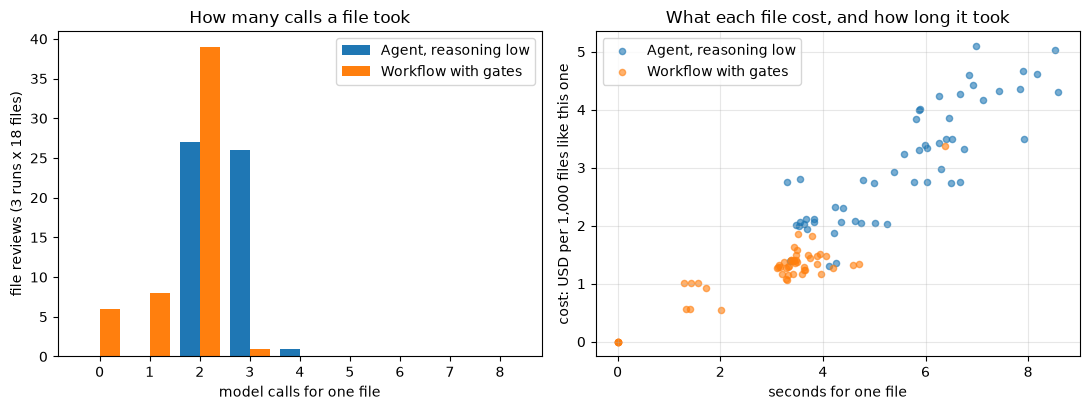

In [12]:
def spread(runs, key, fmt="{:.0f}"):
    vals = [score(r)[key] for r in runs]
    lo, hi = fmt.format(min(vals)), fmt.format(max(vals))
    return lo if lo == hi else f"{lo}-{hi}"

rows = [("Chain, no gates", [chain]), ("Agent, reasoning off", [agent_off]),
        ("Agent, reasoning low", agent_runs), ("Workflow with gates", workflow_runs)]
print(f"{'':22}{'runs':>5}{'routes':>8}{'flags':>7}{'person':>8}{'calls':>7}{'max':>6}{'cost per run':>18}{'s/file':>10}")
print(f"{'':22}{'':>5}{'/' + str(len(FILES)):>8}{'/' + str(len(CONTRACTS)):>7}{'/' + str(len(FOR_PERSON)):>8}{'/run':>7}{'/file':>6}")
for name, runs in rows:
    print(f"{name:22}{len(runs):>5}{spread(runs, 'routes'):>8}{spread(runs, 'flags_exact'):>7}{spread(runs, 'caught'):>8}"
          f"{spread(runs, 'calls'):>7}{spread(runs, 'max_calls'):>6}{'$' + spread(runs, 'cost', '{:.4f}'):>18}{spread(runs, 'seconds', '{:.1f}'):>10}")

def outcome(f, r):
    if r["route"] != f["truth_route"]: return r["route"]
    return "ok" if f["kind"] in ODD or set(r["flags"]) == f["truth_flags"] else "flags"

print(f"\nPer file, run by run ('ok' = right route and exact flags, 'flags' = right route, wrong flags):")
print(f"{'file':6}{'what it is':14}{'truth':10}{'agent, reasoning low':30}workflow with gates")
for f in FILES:
    a = ", ".join(outcome(f, run["results"][f["cid"]]) for run in agent_runs)
    w = ", ".join(outcome(f, run["results"][f["cid"]]) for run in workflow_runs)
    print(f"{f['cid']:6}{f['kind']:14}{f['truth_route']:10}{a:30}{w}")

for name, runs in rows[2:]:
    route_flips = sum(len({run["results"][f["cid"]]["route"] for run in runs}) > 1 for f in FILES)
    flag_flips = sum(len({frozenset(run["results"][f["cid"]]["flags"]) for run in runs}) > 1 for f in CONTRACTS)
    print(f"\n{name}: route changed between runs on {route_flips} files, flag set changed on {flag_flips} contracts")
print(f"Worst case you can state before launch: workflow 3 calls per file (extract, one retry, memo); "
      f"agent {MAX_TURNS} (the turn cap).")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for shift, (name, runs, color) in zip((-0.2, 0.2), [("Agent, reasoning low", agent_runs, "tab:blue"),
                                                  ("Workflow with gates", workflow_runs, "tab:orange")]):
    per_file = [r for run in runs for r in run["results"].values()]
    counts = np.bincount([len(r["usage"]) for r in per_file], minlength=MAX_TURNS + 1)
    ax1.bar(np.arange(MAX_TURNS + 1) + shift, counts, width=0.4, label=name, color=color)
    ax2.scatter([r["seconds"] for r in per_file], [cost(r["usage"]) * 1000 for r in per_file], alpha=0.6, s=20, label=name, color=color)
ax1.set_xticks(range(MAX_TURNS + 1)); ax1.set_xlabel("model calls for one file")
ax1.set_ylabel(f"file reviews ({RUNS} runs x {len(FILES)} files)"); ax1.set_title("How many calls a file took"); ax1.legend()
ax2.set_xlabel("seconds for one file"); ax2.set_ylabel("cost: USD per 1,000 files like this one")
ax2.set_title("What each file cost, and how long it took"); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### The mistakes, one by one

The table counts mistakes. This prints each one with its cause, because the kind of mistake matters as much as the count.

In [13]:
FLAG_TOPICS = {"AUTO_RENEWAL_PRICE_INCREASE": ["renewal", "price_after_renewal"], "UNCAPPED_LIABILITY": ["customer_liability"],
               "LONG_NOTICE": ["notice"], "SHORT_PAYMENT_TERMS": ["payment"]}

def explain(name, f, r):
    wrong = sorted(set(r["flags"]) ^ f["truth_flags"])
    if name.startswith("Agent"):
        if r["route"] != f["truth_route"]: return "memo: " + " ".join(r["memo"].split())[:120]
        return "; ".join(f"flagged {x} on \"{r['flags'][x][:60]}\"" if x in r["flags"] else f"missed {x}" for x in wrong)
    exits = [t for t in r["trace"] if "exit" in t]
    if exits: return exits[0][:130]
    return "; ".join(f"extracted {TOPICS[t][0]}={r['facts'][t][TOPICS[t][0]]} from \"{r['facts'][t]['quote'][:60]}\""
                     for x in wrong for t in FLAG_TOPICS[x])

for name, runs in rows[2:]:
    print(f"{name}:")
    for i, run in enumerate(runs, 1):
        for f in FILES:
            r = run["results"][f["cid"]]
            if outcome(f, r) != "ok":
                print(f"  run {i} {f['cid']} ({f['kind']}): wanted {f['truth_route']}, got {r['route']}. {explain(name, f, r)}")
    print()

Agent, reasoning low:
  run 1 C-01 (typed): wanted standard, got standard. missed UNCAPPED_LIABILITY
  run 1 C-12 (typed): wanted finance, got finance. flagged SHORT_PAYMENT_TERMS on "The Customer shall pay each undisputed invoice within 45 day"
  run 1 C-17 (wrong_file): wanted person, got finance. memo: Auto-renewal is present in Section 5.2 and fees increase by 7% at the start of each Renewal Term, so finance approval is
  run 2 C-12 (typed): wanted finance, got finance. missed LONG_NOTICE
  run 2 C-17 (wrong_file): wanted person, got finance. memo: Finance approval required because the Agreement auto-renews and the Fees increase by 7% at each Renewal Term. Additional
  run 3 C-10 (missing_page): wanted person, got standard. memo: Reviewed the accessible text of the agreement. No auto-renewal price increase, uncapped liability, long notice, or short
  run 3 C-17 (wrong_file): wanted person, got finance. memo: Auto-renewal applies and the renewal term increases the Fees by 7%.

Workf

### What the numbers say, and what they don't

- **Files a person must see.** The workflow sent 4 of 5 to a person in every run. The agent caught 4, 4 and 3. In run 3 it reviewed the contract with the missing page and returned "standard", with a memo that begins "Reviewed the accessible text of the agreement." That is the failure from the hook, made by the agent instead of the chain: a clean-looking result for a file nobody fully read. The workflow is built not to make it: a three-page contract that yields nothing on the required topics never reaches the memo. Neither side caught the wrong supplier in any run.
- **Contracts: here the agent did better.** It put all 13 contracts on the right route in every run. The workflow managed 12, 12 and 13. Both of its route misses are C-13, one of the two contracts whose cap covers the Supplier only: the extractor found no sentence on the Customer's liability, and the sanity gate sent the file to a person. That failure is safe, since a person looks, but it spends a person's time on a contract the agent handled.
- **A gate that passed a wrong answer.** The workflow's other repeated mistake is quieter. On C-01, the other Supplier-only cap, it quoted the Supplier's cap as the Customer's liability in runs 1 and 3, read it as limited, and missed the flag. The quote was real, so the grounding gate passed it. A grounding gate proves a quote exists, not that it is the right sentence. The agent, reading the whole liability section at once, got the liability flag right on these two contracts in 5 of its 6 tries.
- **Exact flags were close:** 11 to 13 of 13 for the agent, 11 to 12 for the workflow. Every workflow flag mistake came from extraction, never from the rules, which are code. The agent's came from both reading (a missed liability flag on C-01 in run 1, a missed long-notice flag on C-12 in run 2) and comparing (a short-payment flag on 45 days, C-12 in run 1).
- **Cost, calls and time.** The workflow cost $0.0198 to $0.0228 per run of 18 files, the agent $0.0541 to $0.0565, about 2.6 times as much. It made 29 to 31 calls per run against 44 to 46, and took 2.9 to 3.0 seconds per file against 5.3 to 6.1. Part of the gap is the text gate, which spends nothing on the scan and the partial file. The rest is that each workflow call does one small job, while every agent turn re-sends the policy and the tools, and every turn after the first re-sends the contract too.
- **Predictability.** In the left chart, the workflow took 0, 1 or 2 calls per file, and once 3 for the retry: which gate stopped a file sets its count. The agent took 2 to 4. The workflow's worst case is 3 calls, known before launch. The agent's is the turn cap of 8, and the reasoning-off run hit it. In the right chart, the agent's per-file costs spread out, while the workflow's sit in a tight band. Run to run, though, both changed a route on one file and a flag set on two contracts. At this size the workflow was more stable in its path and its price, not visibly more stable in its answers.
- **What this does not show.** 18 synthetic files (the typed contracts are about 630 tokens each) and three runs per pipeline are enough to see the kinds of mistakes, not to rank two pipelines that differ by one or two files. It is one model, with one prompt for each side. A sharper instruction might make the agent stop on the missing page every time, and reasoning on the extraction node alone might find the Supplier-only clause. Both are cheap experiments, listed at the end.

## 7. The file nobody wrote a gate for

The chain, the agent with reasoning and the gated workflow all sent C-17 to finance, in every run. The file is a clean contract. It just names Kestrel Freight, and the purchase record says Tidewater IT Support. The agent had the supplier's name in its task and read the contract, parties clause included, in every run, and it still routed the file to finance.

This is how gates get added in practice: a failure shows up, and you write the check for it once. The extraction node already writes the supplier's name into the state, so the new gate can be tested on the three saved workflow runs with no model call at all. The name match is fuzzy, so OCR typos in a supplier's name still pass.

In [14]:
def gate_supplier(state):
    # New gate: the supplier the contract names must match the purchase record (fuzzy, so OCR typos pass).
    named, record = state["facts"]["supplier"], state["supplier"]
    if SequenceMatcher(None, norm(named), norm(record)).ratio() < 0.8:
        return "exit", f"the contract names {named!r}, the purchase record says {record!r}"
    return "pass", ""

# No new model calls: the extraction node already wrote the supplier's name into each run's state.
for i, run in enumerate(workflow_runs, 1):
    stopped = []
    for cid, r in run["results"].items():
        if r["route"] != "person":                       # the files that got past every existing gate
            verdict, why = gate_supplier({"facts": r["facts"], "supplier": BY_ID[cid]["supplier"]})
            if verdict == "exit": stopped.append(f"{cid}: {why}")
    print(f"Run {i}: the new gate stops {stopped or 'nothing'}")

spent = sum(cost([u for r in run["results"].values() for u in r["usage"]]) for _, runs in rows for run in runs)
print(f"\nTotal API spend for this notebook: ${spent:.3f}")

Run 1: the new gate stops ["C-17: the contract names 'Kestrel Freight', the purchase record says 'Tidewater IT Support'"]
Run 2: the new gate stops ["C-17: the contract names 'Kestrel Freight', the purchase record says 'Tidewater IT Support'"]
Run 3: the new gate stops ["C-17: the contract names 'Kestrel Freight', the purchase record says 'Tidewater IT Support'"]

Total API spend for this notebook: $0.325


The new gate stopped C-17 in all three saved runs and nothing else, for zero model calls.

## The fact to walk away with

On this job, the fixed workflow with gates cost about 40% of what the agent cost, took about half the time per file, never spent more than three calls on a file, and sent every unreadable file to a person in every run. The agent was better at one thing that matters: it read an unusual liability clause correctly where the workflow's extractor failed, sometimes loudly and sometimes silently. Neither one noticed a contract from the wrong supplier until code was written for it, and that code then caught it in every saved run for free.

So build the fixed path first, put a gate wherever a bad result would be expensive to carry forward, and test the gates like code. Where you cannot draw the path, or where one node keeps failing on inputs that need judgment, put an agent in that one node and keep the gates on both sides of it. And re-run the comparison when the model changes. With reasoning off, the same agent was worse and more expensive, and labs now advise folding some hand-built structure back into a single agent as models improve ([Anthropic, 2026](https://claude.com/resources/articles/building-agents-when-to-fold-subagents-into-your-main-agent-loop)). Keep a piece of structure only where your own eval set scores worse without it.

What to try next:

- **Make the agent a node, not the whole path.** Keep the text gate in front and the rules and the supplier gate behind. When the sanity gate fails, hand that file's extraction to an agent instead of a person, and send the agent's answer through the same extraction gate. That targets C-13's failure. Watch the missing page, though: this agent let it through once in three runs.
- **Turn reasoning on for the extraction node only** (`effort="low"` in the `call_model` call inside `extract`), and see whether it finds the Supplier-only clause. That is one node's eval, not a rewrite.
- **Check what a quote says, not only that it exists.** For the liability topic, require in code that the quote names the Customer or says "each party", and see whether C-01's silent miss turns into a retry.
- **Wire `gate_supplier` into `gate_extraction`**, add one more kind of broken file of your own, and see which side notices it first.

---
📖 **Want the decisions behind agents like this one, explained without code?** [*AI Agents Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-agents-tutorials--workflows-first-from-scratch&click=book-nb-agents&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0HNXRSRH2%3Fmaas%3Dmaas_adg_api_580351185840460851_static_9_573%26ref_%3Daa_maas%26tag%3Dmaas%26aa_campaignid%3Dagents-en%26aa_adgroupid%3Dgithub-notebook%26aa_creativeid%3Dgenai-workflows-first&retarget=0&text=book-nb-agents) by the author of this repository has a full chapter on workflows first: the gate between steps, the five workflow shapes, why the fixed path wins, and the signs a workflow has outgrown itself. Available on Amazon.

![](https://europe-west1-genai-agents-views-tracker.cloudfunctions.net/genai-agents-tracker?notebook=all-agents-tutorials--workflows-first-from-scratch)